# Slurm GPU smoke test

A small PyTorch workload to test RODE's Slurm notebook execution, streamed output,
GPU access, and persistent kernel state. It uses synthetic data and one visible
GPU; the default GPU workload runs for about five seconds.

1. On the cluster login host, use **Allocate… → Reserve for notebooks** and request
   **one GPU**. Wait until the allocation is running.
2. Open **Kernel settings**, select your Python environment, click
   **Refresh Slurm targets**, and select the allocation under **Execution target**.
3. Choose **Run all**. The first cells print the compute hostname, job ID,
   interpreter, and visible GPU. Execution stops if the job or GPU is missing.

The selected environment must be available on the compute node and contain
`jupyter_client`, `ipykernel`, and a PyTorch build compatible with that node's
GPU drivers. `matplotlib` is optional for the loss plot. This notebook does not
install packages or download data.

In [1]:
# Set REQUIRE_SLURM = False only if you want to try a local GPU instead.
REQUIRE_SLURM = True
MATRIX_SIZE = 1024
WORKLOAD_SECONDS = 5.0
TRAINING_STEPS = 40

## 1. Check execution placement

The hostname should be a compute node, and `SLURM_JOB_ID` should match the
allocation selected in RODE. The interpreter should belong to the environment
you selected. Slurm controls GPU visibility; do not override it in this notebook.

In [2]:
import os
import socket
import sys
import uuid
from pathlib import Path

if "smoke_session_token" not in globals():
    smoke_session_token = uuid.uuid4().hex[:12]

print(f"Hostname:    {socket.gethostname()}")
print(f"Python:      {sys.executable}")
print(f"Directory:   {Path.cwd()}")
print(f"Kernel PID:  {os.getpid()}")
print(f"State token: {smoke_session_token}")
for name in (
    "SLURM_JOB_ID",
    "SLURM_STEP_ID",
    "SLURM_JOB_NODELIST",
    "SLURM_JOB_GPUS",
    "SLURM_STEP_GPUS",
    "CUDA_VISIBLE_DEVICES",
    "ROCR_VISIBLE_DEVICES",
):
    print(f"{name}: {os.environ.get(name, '(unset)')}")

if REQUIRE_SLURM and not os.environ.get("SLURM_JOB_ID"):
    raise RuntimeError(
        "This kernel is not inside a Slurm job. In Kernel settings, select "
        "the running GPU allocation under Execution target, then Run all again."
    )

Hostname:    sv1225
Python:      /home/pbenner/Env/rode/.venv/bin/python
Directory:   /home/pbenner/Env/rode
Kernel PID:  1122206
State token: 726c5ef065c0
SLURM_JOB_ID: 12837
SLURM_STEP_ID: 0
SLURM_JOB_NODELIST: sv1225
SLURM_JOB_GPUS: (unset)
SLURM_STEP_GPUS: 0
CUDA_VISIBLE_DEVICES: 0
ROCR_VISIBLE_DEVICES: (unset)


## 2. Check the GPU and a calculation

PyTorch uses `cuda:0` for the first GPU visible to this job, including on supported
ROCm builds. This may differ from its physical GPU index. The calculation below
compares GPU results with a known CPU result.

In [3]:
try:
    import torch
except ImportError as error:
    raise RuntimeError(
        "PyTorch is missing from this kernel. Select an environment with a "
        "GPU-enabled PyTorch installation available on the compute node."
    ) from error

print(f"PyTorch: {torch.__version__}")
print(f"CUDA build: {torch.version.cuda}")
print(f"ROCm build: {getattr(torch.version, 'hip', None)}")
if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch cannot access a GPU. Check the selected Slurm allocation, "
        "its GPU request, the PyTorch build, and GPU device access in the sandbox."
    )

print(f"Visible GPUs: {torch.cuda.device_count()}")
for index in range(torch.cuda.device_count()):
    properties = torch.cuda.get_device_properties(index)
    print(
        f"  cuda:{index}: {properties.name}, "
        f"{properties.total_memory / 1024**3:.1f} GiB total memory"
    )

device = torch.device("cuda:0")
torch.manual_seed(42)
sample = torch.arange(1024, dtype=torch.float32, device=device)
actual = sample * 3 + 7
expected = torch.arange(1024, dtype=torch.float32) * 3 + 7
torch.testing.assert_close(actual.cpu(), expected)
print(f"PASS: calculation ran on {actual.device} and matched the CPU result.")

PyTorch: 2.15.0+cu132
CUDA build: 13.2
ROCm build: None


Visible GPUs: 1
  cuda:0: NVIDIA H100 80GB HBM3, 79.2 GiB total memory


PASS: calculation ran on cuda:0 and matched the CPU result.


## 3. Run a short matrix workload

Two 1024 × 1024 float32 inputs and their result occupy about 12 MiB, plus library
workspace. Progress is printed roughly once per second. Increase
`WORKLOAD_SECONDS` in the first cell if you want more time to inspect GPU activity
or test **Interrupt**. The timing is a smoke-test measurement, not a benchmark.

In [4]:
import time

assert MATRIX_SIZE > 0 and WORKLOAD_SECONDS > 0
matrix_a = torch.randn(MATRIX_SIZE, MATRIX_SIZE, device=device)
matrix_b = torch.randn(MATRIX_SIZE, MATRIX_SIZE, device=device)

# Warm up the GPU library, then synchronize so timing includes completed work.
for _ in range(3):
    matrix_result = matrix_a @ matrix_b
torch.cuda.synchronize(device)

iterations = 0
started = time.perf_counter()
last_report = started
while time.perf_counter() - started < WORKLOAD_SECONDS:
    matrix_result = matrix_a @ matrix_b
    torch.cuda.synchronize(device)
    iterations += 1
    now = time.perf_counter()
    if now - last_report >= 1.0:
        print(f"GPU work: {now - started:.1f} s, {iterations} products", flush=True)
        last_report = now

elapsed = time.perf_counter() - started
assert torch.isfinite(matrix_result).all().item(), "Non-finite matrix result"
print(f"PASS: {iterations} matrix products completed on {matrix_result.device}.")
print(f"Elapsed: {elapsed:.2f} s; average: {1000 * elapsed / iterations:.3f} ms/product")
print(f"PyTorch allocated memory: {torch.cuda.memory_allocated(device) / 1024**2:.1f} MiB")

GPU work: 1.0 s, 14527 products


GPU work: 2.0 s, 29090 products


GPU work: 3.0 s, 43577 products


GPU work: 4.0 s, 58032 products


PASS: 72561 matrix products completed on cuda:0.
Elapsed: 5.00 s; average: 0.069 ms/product
PyTorch allocated memory: 12.0 MiB


## 4. Test gradients and parameter updates

Fit a tiny linear model to synthetic data on the GPU. The loss should decrease
substantially; no dataset files or network access are needed.

In [5]:
assert TRAINING_STEPS >= 20, "Use at least 20 steps for the loss-decrease check."
features = torch.randn(512, 8, device=device)
true_weights = torch.arange(1, 9, dtype=torch.float32, device=device).reshape(8, 1) / 8
targets = features @ true_weights + 0.25
model = torch.nn.Linear(8, 1).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
loss_function = torch.nn.MSELoss()
loss_history = []

with torch.no_grad():
    initial_loss = loss_function(model(features), targets).item()

for step in range(1, TRAINING_STEPS + 1):
    optimizer.zero_grad()
    loss = loss_function(model(features), targets)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step == 1 or step % 10 == 0 or step == TRAINING_STEPS:
        print(f"Step {step:3d}: loss = {loss_history[-1]:.6f}", flush=True)

with torch.no_grad():
    final_loss = loss_function(model(features), targets).item()
assert final_loss < initial_loss * 0.2, "Training loss did not decrease as expected."
print(f"PASS: loss decreased from {initial_loss:.6f} to {final_loss:.6f}.")
print(f"Parameters and gradients are on {model.weight.device} and {model.weight.grad.device}.")

Step   1: loss = 2.725069


Step  10: loss = 0.072945


Step  20: loss = 0.001707


Step  30: loss = 0.000048


Step  40: loss = 0.000002


PASS: loss decreased from 2.725069 to 0.000001.
Parameters and gradients are on cuda:0 and cuda:0.


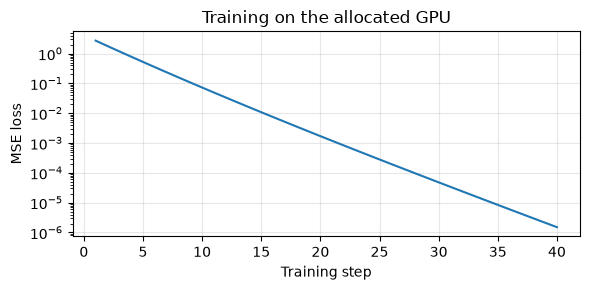

In [6]:
# Optional: exercise inline notebook image output.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Skipping the plot: matplotlib is not installed. GPU checks passed above.")
else:
    figure, axis = plt.subplots(figsize=(6, 3))
    axis.semilogy(range(1, len(loss_history) + 1), loss_history)
    axis.set(xlabel="Training step", ylabel="MSE loss", title="Training on the allocated GPU")
    axis.grid(True, alpha=0.3)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

## 5. Test kernel persistence

Run the cell below, then save the notebook. Enable **Persist kernel**, use
**Detach kernel**, and reattach from the notebook or **Sessions**. Run only this
last cell again: the token and PID should stay the same and the counter should
increase. Accessing the existing GPU result also checks that its tensor survived.

Keep the allocation running during this check. When finished, **Shut down kernel**
and separately use **Release allocation** to return the Slurm resources.

In [7]:
persistence_counter = globals().get("persistence_counter", 0) + 1
print(f"State token: {smoke_session_token}; kernel PID: {os.getpid()}")
print(f"Persistence check count: {persistence_counter}")
print(f"Existing GPU tensor: {tuple(matrix_result.shape)} on {matrix_result.device}")
print(f"Existing tensor sample: {matrix_result[0, 0].item():.6f}")
print(f"Trained model loss: {final_loss:.6f}")

State token: 726c5ef065c0; kernel PID: 1122206
Persistence check count: 1
Existing GPU tensor: (1024, 1024) on cuda:0
Existing tensor sample: 5.710278
Trained model loss: 0.000001
